# Figure 2 - Figure Code

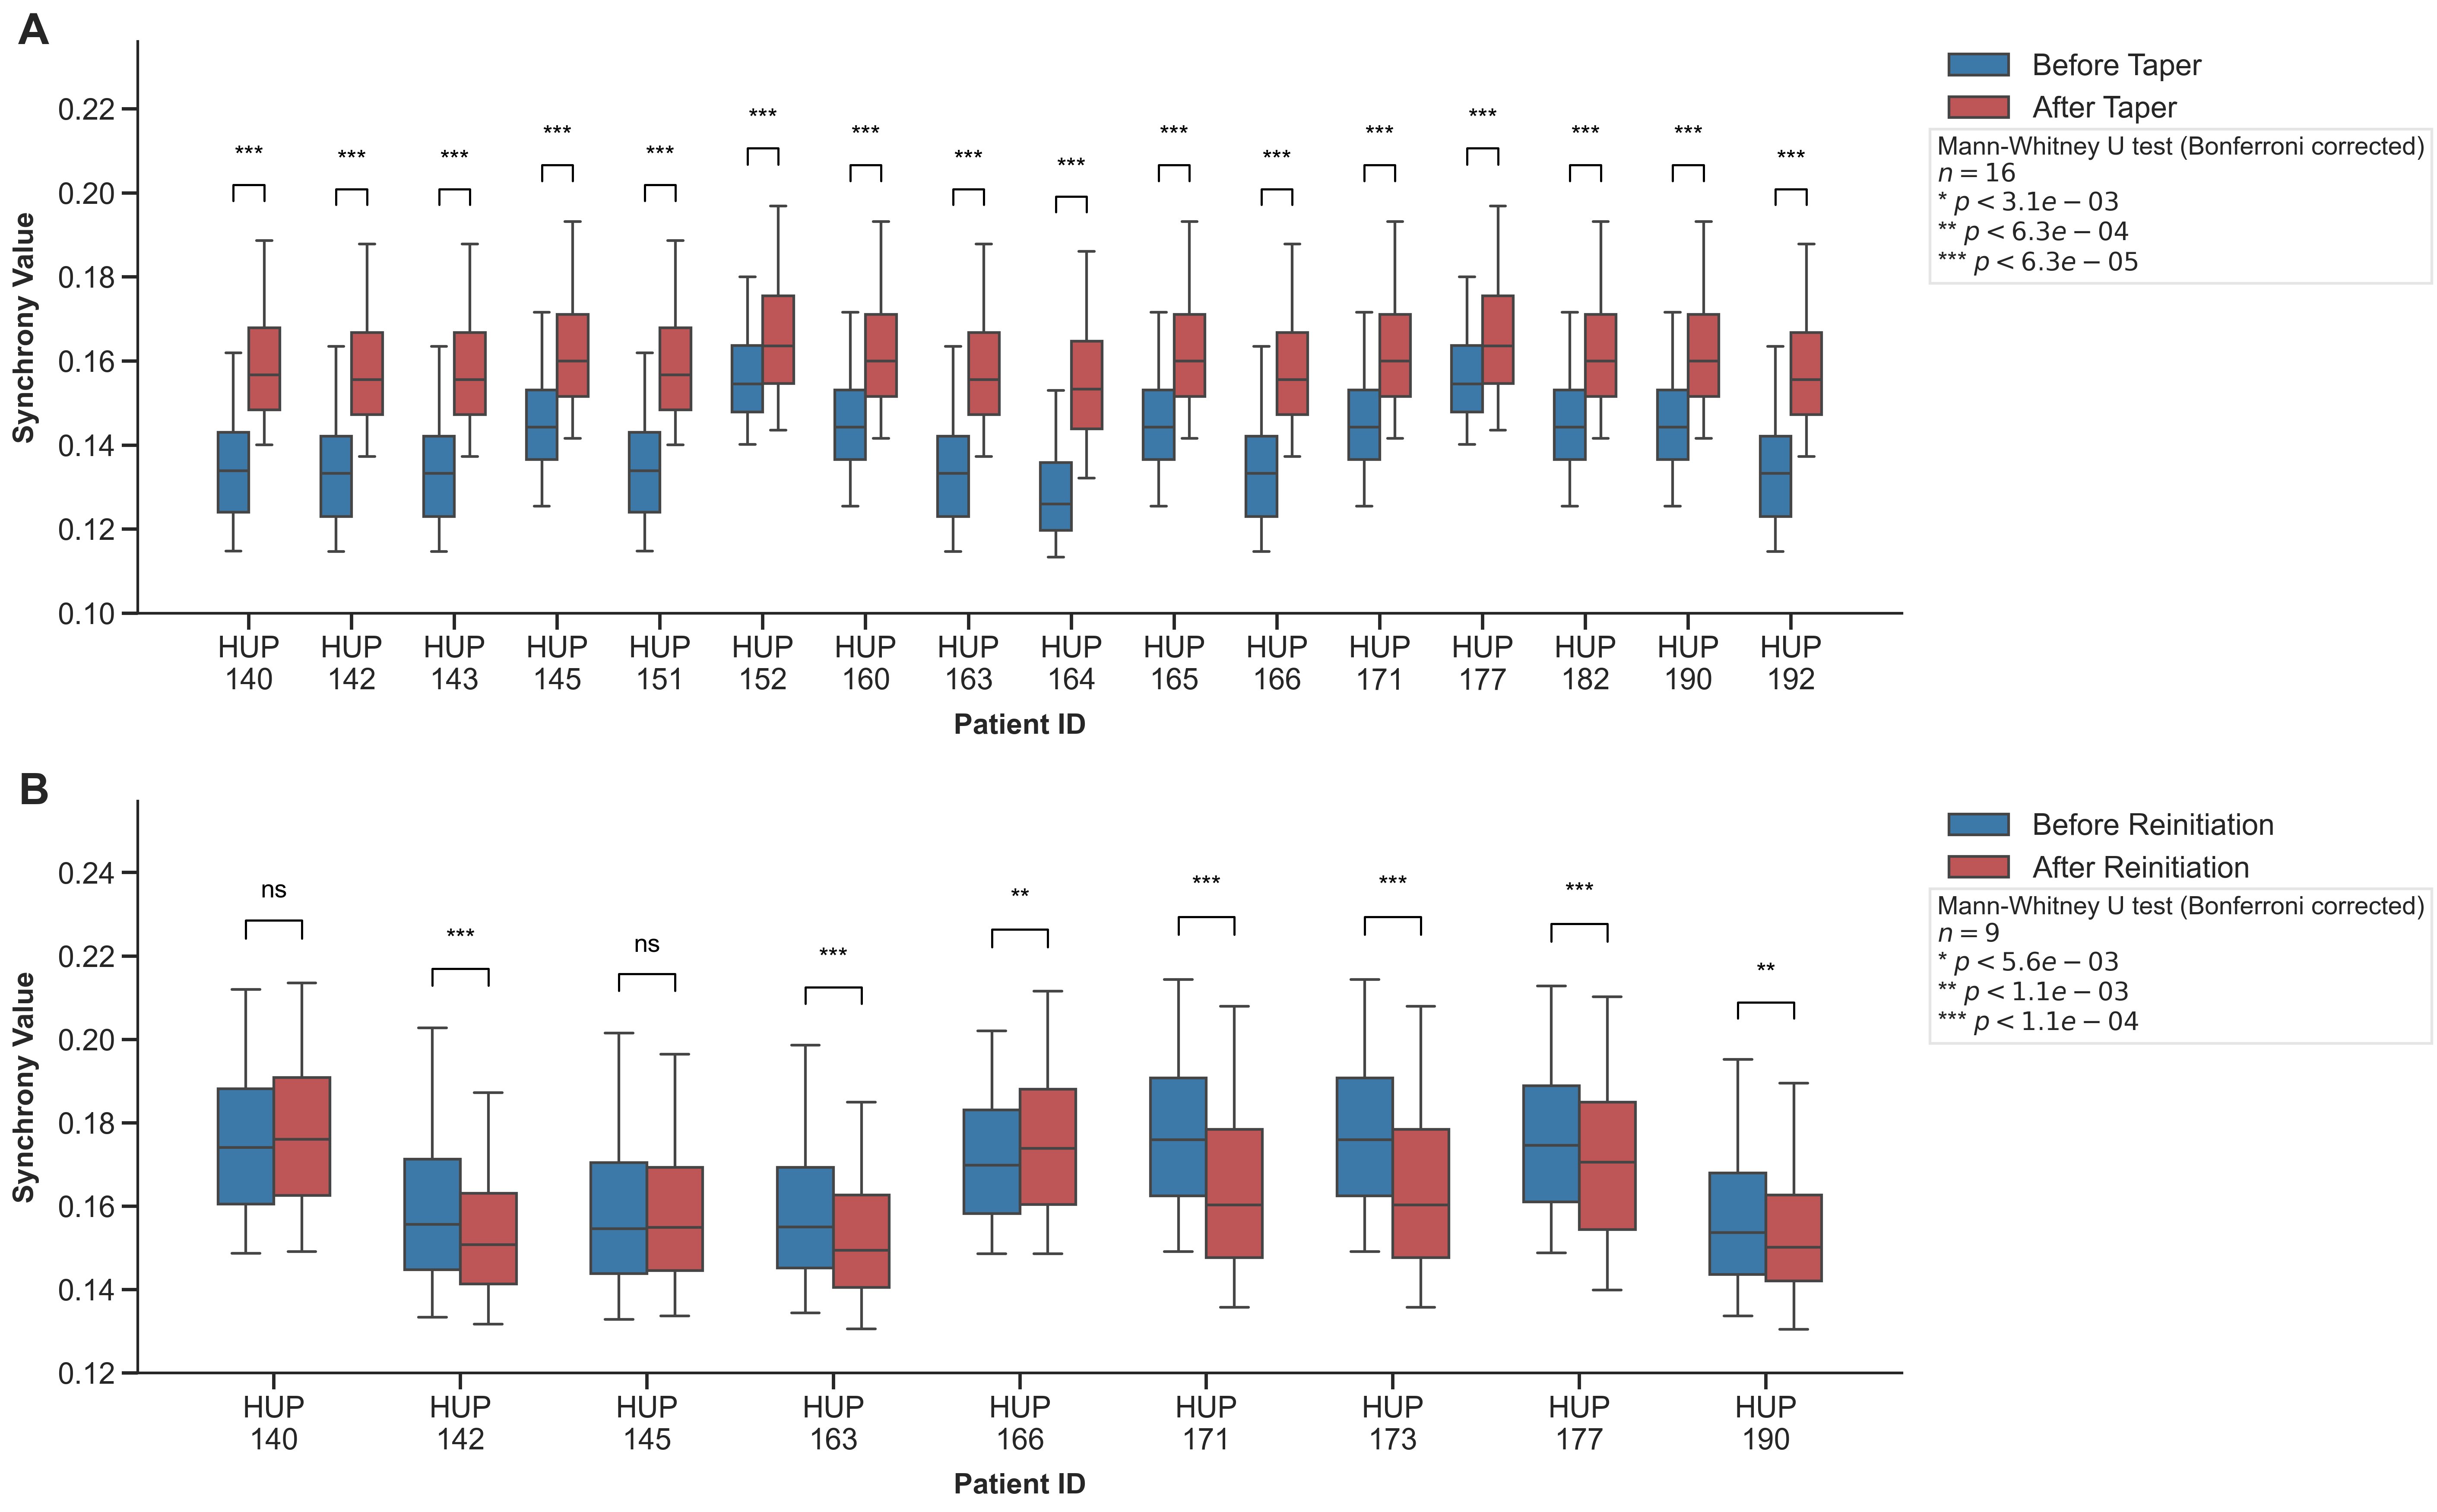

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from matplotlib.lines import Line2D

# --- Configuration ---
DATA_PATH = "../../cnt-data/"
patient_hup_id = 142 

# ==========================================
# PART A: DATA PREPARATION (Taper)
# ==========================================

# Load taper_annotations.csv
taper_df = pd.read_csv(os.path.join(DATA_PATH, "taper_annotations.csv"))
taper_df = taper_df.dropna(subset=["taper_start_hr"])
taper_df = taper_df.drop(columns=["reinit_start_hr"]).reset_index(drop=True)

# Initialize dictionaries for A
before_synchronies_dict_a = {}
after_synchronies_dict_a = {}

unique_hup_ids_a = sorted(taper_df["hup_id"].unique())
hup_id_to_index_a = {hup_id: index for index, hup_id in enumerate(unique_hup_ids_a)}

for index, row in taper_df.iterrows():
    hup_id = int(row["hup_id"])
    taper_start_hr = int(row["taper_start_hr"])
    taper_start_time = taper_start_hr * 60

    hourly_patient_features_df = pd.read_csv(
        os.path.join(DATA_PATH, f"giant_new_tables/HUP_{str(patient_hup_id)}.csv")
    )

    first_seizure_time = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] > taper_start_time)
        & (hourly_patient_features_df["had_seizure"] >= 1)
    ]["emu_minute"].min()

    after_period = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] >= taper_start_time)
        & (hourly_patient_features_df["emu_minute"] < first_seizure_time)
    ]
    after_synchronies = after_period["synchrony_broadband"].values

    before_period = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] < taper_start_time)
        & (~hourly_patient_features_df["synchrony_broadband"].isna())
    ].tail(len(after_synchronies))
    before_synchronies = before_period["synchrony_broadband"].values

    before_synchronies = before_synchronies[~np.isnan(before_synchronies)]
    after_synchronies = after_synchronies[~np.isnan(after_synchronies)]

    hup_index = hup_id_to_index_a[hup_id]
    if hup_index not in before_synchronies_dict_a:
        before_synchronies_dict_a[hup_index] = []
        after_synchronies_dict_a[hup_index] = []

    before_synchronies_dict_a[hup_index].extend(before_synchronies)
    after_synchronies_dict_a[hup_index].extend(after_synchronies)

# Structure Data for Plotting A
data_rows_a = []
for hup_index in sorted(before_synchronies_dict_a.keys()):
    hup_id = unique_hup_ids_a[hup_index]
    for val in before_synchronies_dict_a[hup_index]:
        data_rows_a.append({
            "HUP ID": f"HUP\n{hup_id}", 
            "Condition": "Before Taper", 
            "Synchrony": val,
            "ID_Sort": hup_index 
        })
    for val in after_synchronies_dict_a[hup_index]:
        data_rows_a.append({
            "HUP ID": f"HUP\n{hup_id}", 
            "Condition": "After Taper", 
            "Synchrony": val,
            "ID_Sort": hup_index
        })

df_plot_a = pd.DataFrame(data_rows_a)
df_plot_a = df_plot_a.sort_values("ID_Sort")


# ==========================================
# PART B: DATA PREPARATION (Reinitiation)
# ==========================================

reinit_df = pd.read_csv(os.path.join(DATA_PATH, "taper_annotations.csv"))
reinit_df = reinit_df.dropna(subset=["reinit_start_hr"])
reinit_df = reinit_df.drop(columns=["taper_start_hr"]).reset_index(drop=True)
reinit_df = reinit_df[reinit_df["hup_id"] != 152]

# Initialize dictionaries for B
before_synchronies_dict_b = {}
after_synchronies_dict_b = {}

unique_hup_ids_b = sorted(reinit_df["hup_id"].unique())
hup_id_to_index_b = {hup_id: index for index, hup_id in enumerate(unique_hup_ids_b)}

for index, row in reinit_df.iterrows():
    hup_id = int(row["hup_id"])
    reinit_start_hr = int(row["reinit_start_hr"])
    reinit_start_time = reinit_start_hr * 60

    hourly_patient_features_df = pd.read_csv(
        os.path.join(DATA_PATH, f"giant_new_tables/HUP_{str(patient_hup_id)}.csv")
    )

    before_period = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] < reinit_start_time)
        & (~hourly_patient_features_df["synchrony_broadband"].isna())
    ].tail(720)
    before_synchronies = before_period["synchrony_broadband"].values

    after_period = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] >= reinit_start_time)
        & (~hourly_patient_features_df["synchrony_broadband"].isna())
    ].head(720)
    after_synchronies = after_period["synchrony_broadband"].values

    before_synchronies = before_synchronies[~np.isnan(before_synchronies)]
    after_synchronies = after_synchronies[~np.isnan(after_synchronies)]

    hup_index = hup_id_to_index_b[hup_id]
    if hup_index not in before_synchronies_dict_b:
        before_synchronies_dict_b[hup_index] = []
        after_synchronies_dict_b[hup_index] = []

    before_synchronies_dict_b[hup_index].extend(before_synchronies)
    after_synchronies_dict_b[hup_index].extend(after_synchronies)

# Structure Data for Plotting B
data_rows_b = []
for hup_index in sorted(before_synchronies_dict_b.keys()):
    hup_id = unique_hup_ids_b[hup_index]
    for val in before_synchronies_dict_b[hup_index]:
        data_rows_b.append({
            "HUP ID": f"HUP\n{hup_id}", 
            "Condition": "Before Reinitiation", 
            "Synchrony": val,
            "ID_Sort": hup_index 
        })
    for val in after_synchronies_dict_b[hup_index]:
        data_rows_b.append({
            "HUP ID": f"HUP\n{hup_id}", 
            "Condition": "After Reinitiation", 
            "Synchrony": val,
            "ID_Sort": hup_index
        })

df_plot_b = pd.DataFrame(data_rows_b)
df_plot_b = df_plot_b.sort_values("ID_Sort")


# ==========================================
# COMBINED PLOTTING
# ==========================================

sns.set_theme(style="ticks", context="talk")

max_patients = max(len(unique_hup_ids_a), len(unique_hup_ids_b))
fig_width = max(8, max_patients * 1.2)
fig_height = 12 

fig, axes = plt.subplots(2, 1, figsize=(fig_width, fig_height), dpi=300)

# --- HELPER FUNCTION FOR PLOTTING ---
def plot_panel(ax, df, before_dict, after_dict, unique_ids, palette_colors, n_tests, label):
    # Boxplot
    sns.boxplot(
        data=df,
        x="HUP ID",
        y="Synchrony",
        hue="Condition",
        width=0.6,
        palette=palette_colors,
        whis=(5, 95),       
        showfliers=False,  
        linewidth=1.5,
        ax=ax
    )

    # Stats
    bonferroni_05 = 0.05 / n_tests
    bonferroni_01 = 0.01 / n_tests
    bonferroni_001 = 0.001 / n_tests

    x_locs = ax.get_xticks()
    y_max_limit = 0 

    for idx, (hup_index, x_loc) in enumerate(zip(sorted(before_dict.keys()), x_locs)):
        data_before = before_dict[hup_index]
        data_after = after_dict[hup_index]

        u_stat, p_val = mannwhitneyu(data_before, data_after, alternative="two-sided")

        if p_val < bonferroni_001:
            sig_symbol = "***"
        elif p_val < bonferroni_01:
            sig_symbol = "**"
        elif p_val < bonferroni_05:
            sig_symbol = "*"
        else:
            sig_symbol = "ns"

        max_val = max(
            np.percentile(data_before, 95), 
            np.percentile(data_after, 95)
        )

        bar_h = max_val + (max_val * 0.05)
        bar_tips = bar_h + (max_val * 0.02)
        text_h = bar_tips + (max_val * 0.02)

        if text_h > y_max_limit:
            y_max_limit = text_h

        x_before = x_loc - 0.15
        x_after = x_loc + 0.15

        ax.plot([x_before, x_before, x_after, x_after], [bar_h, bar_tips, bar_tips, bar_h], lw=1.2, c="black")
        ax.text((x_before + x_after)/2, text_h, sig_symbol, ha='center', va='bottom', color="black", fontsize=14)

    # Formatting
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title=None, frameon=False)
    
    stats_explanation = (
        f"Mann-Whitney U test (Bonferroni corrected)\n"
        f"$n={n_tests}$\n"
        f"* $p < {bonferroni_05:.1e}$\n"
        f"** $p < {bonferroni_01:.1e}$\n"
        f"*** $p < {bonferroni_001:.1e}$"
    )
    
    # --- CHANGE: Fontsize increased to 14 here ---
    ax.text(1.02, 0.6, stats_explanation, transform=ax.transAxes, fontsize=14, 
             bbox=dict(facecolor='white', alpha=0.5, edgecolor='#cccccc'))

    ax.set_ylabel("Synchrony Value", labelpad=10, fontsize=16, fontweight='bold')
    ax.set_xlabel("Patient ID", labelpad=10, fontsize=16, fontweight='bold')
    
    # Y-limits
    lower_lim = 0.10 if label == "A" else 0.12
    ax.set_ylim(bottom=lower_lim, top=y_max_limit * 1.1)
    
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['left'].set_linewidth(1.5)
    
    # Add Panel Label (A or B)
    ax.text(-0.05, 1.05, label, transform=ax.transAxes, 
            fontsize=24, fontweight='bold', va='top', ha='right')


# --- PLOT PANEL A ---
plot_panel(
    ax=axes[0],
    df=df_plot_a,
    before_dict=before_synchronies_dict_a,
    after_dict=after_synchronies_dict_a,
    unique_ids=unique_hup_ids_a,
    palette_colors={"Before Taper": "#2b7bba", "After Taper": "#cf4446"},
    n_tests=len(unique_hup_ids_a),
    label="A"
)

# --- PLOT PANEL B ---
plot_panel(
    ax=axes[1],
    df=df_plot_b,
    before_dict=before_synchronies_dict_b,
    after_dict=after_synchronies_dict_b,
    unique_ids=unique_hup_ids_b,
    palette_colors={"Before Reinitiation": "#2b7bba", "After Reinitiation": "#cf4446"},
    n_tests=len(reinit_df),
    label="B"
)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()